# Lab 4 - Kernel Regularized Least Squares

In this lab activity we consider the extension of regularized least squares to non-linear problems using kernel functions.

A brief summary of the tasks:
 1. Generate a simple non-linear data-set
 2. Use **linear** RLS to try and learn with such dataset
 3. Use a **feature transformation** for learning with non-linear data
 4. Implement various kernel functions
 5. Implement kernel RLS
 6. Generate a more complex non-linear data-set
 7. Use kernel RLS for learning on non-linear data, use cross-validation to find the best hyperparameters.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib as cm
import matplotlib.pyplot as plt
import scipy.linalg
import scipy.spatial
import os

In [2]:
def calc_err(Ypred, Ytrue):
    return np.mean((Ypred-Ytrue)**2)

# Part 1: Learning with a simple non-linear dataset

## Generate quadratic data

In this lab we are going to use regression datasets where the target `Y` is **not a linear function** of the inputs `X`.

As a first example, see the following function to generate quadratic data.

In [3]:
def quadratic_data_gen(n, w, sigma_noise):
    X = np.random.uniform(-3, 3, size=(n, 1))
    Xsq = X ** 2
    noise = np.random.normal(0, sigma_noise, size=(n, 1))

    # Here we can use scalar multiplication since in dimension 1
    Y = Xsq * w + noise

    return X, Y

Shape of x: (100, 1), shape of y: (100, 1)


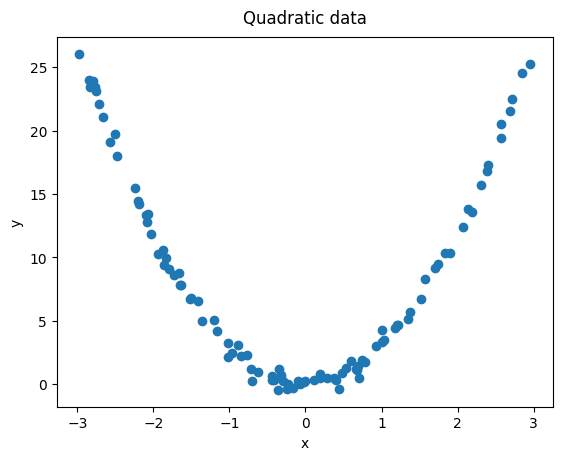

In [4]:
x_tr, y_tr = quadratic_data_gen(100, np.array([3]), 0.5)

print(f"Shape of x: {x_tr.shape}, shape of y: {y_tr.shape}")
fig, ax = plt.subplots()
ax.scatter(x_tr, y_tr)
ax.set_title('Quadratic data', pad=10)
ax.set_xlabel('x')
ax.set_ylabel('y')
fig.show()

## Task 1: Linear RLS

The implementation of linear regularized least-squares is given below in the functions `rls_train` and `rls_predict`.

Remember: regularized least-squares has the following form

$$(X_{tr}^\top X_{tr} + \lambda n I)w = X_{tr}^\top Y_{tr}$$


Tasks:
 - Use RLS to train a linear regressor for the quadratic data. Comment on the results.

In [5]:
def rls_train(x, y, reg_par):
    cov = x.T @ x + reg_par * x.shape[0] * np.eye(x.shape[1])
    rhs = x.T @ y
    w = np.linalg.solve(cov, rhs)
    return w

def rls_predict(x, w):
    return x @ w

[[-1.67040096]] (100, 1) (100, 1)


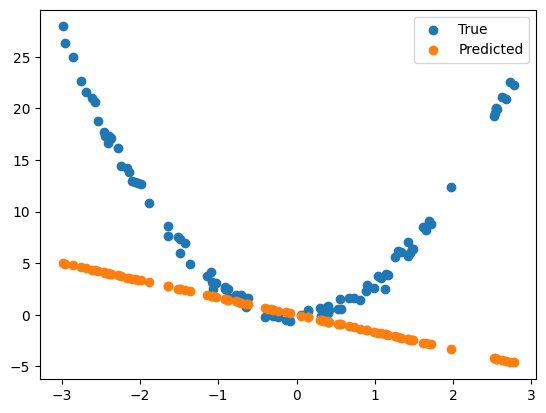

In [6]:
#DATI DI INPUT QUADRATICI , USIAMO UN REGRESSORE LINEARE PER APPROSSIMARE I DATI

x_tr, y_tr = quadratic_data_gen(100, np.array([3]), 0.5)
#x unidimensionale in un intervallo di R, facendo regr lineare cerchiamo un w in R
#che minimizzi una quadratica, con Ynew=w*xnew , approx di merda . trucco delle feature map
#e dei kernel : se so che f* è un polinomio invece di considerare solo le c considero un
#vettore con tutti i gli esponenti di x (1,x,x^2). quindi cercherò un w app a R^c con c grado
#di x e minimizzo quadratica (VD FOTO). e se non so niente su f* considero feature infinte
#Uso algoritmi per la regressione lineare (stessa idea) per f* non lineari
#ovviamente con procedimenti diversi

w = rls_train(x_tr, y_tr, reg_par=0.001)
print(w, np.shape(x_tr), np.shape(y_tr))
pred_tr = rls_predict(x_tr, w)

fig, ax = plt.subplots()
ax.scatter(x_tr, y_tr, label="True")
ax.scatter(x_tr, pred_tr, label="Predicted")
ax.legend(loc="best");

## Task 2: Feature transform

There is a simple way to use a linear algorithm for learning non-linear data: transforming the input data in such a way to convert the problem into a linear one.

This is a simple fix in some cases, but becomes cumbersome if the datasets are non-linear in a complex way.

Here we adopt this approach to train a RLS classifier with the quadratic dataset:
 1. Generate the quadratic dataset
 2. Transform the data so that it becomes a (n, 2) matrix containing the original input, and a transformed version of itself. Clearly the correct transformation depends on the underlying function (a quadratic function!).
 3. Use the RLS algorithm on the new dataset
 4. Plot **and comment** on the results

In [7]:
x_tr, y_tr = quadratic_data_gen(100, np.array([3]), 0.5)

# Instead of just the given xs build a feature matrix with the xs and their squares:
# ones = np.ones((x_tr.shape[0],1))
trsf_x_tr = np.concatenate([x_tr, x_tr**2], axis=1) #potrei aggiungere anche gli ones per raggiungere la forma completa di una funzione quadratica
print(np.shape(trsf_x_tr))

(100, 2)


[[-1.67040096]]


Text(0.5, 1.0, 'Fitting quadratic data with Feature Map')

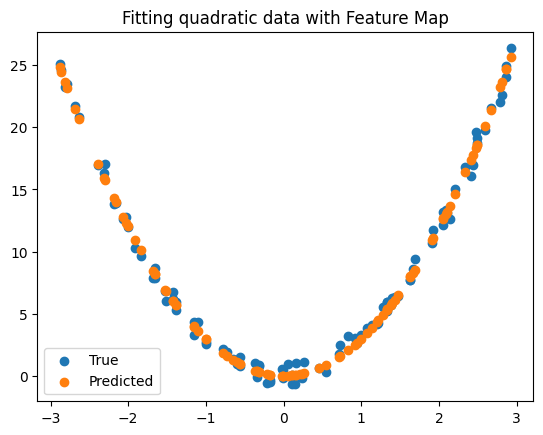

In [8]:
# Now train a linear regression function on the new data!
trsf_w_rls = rls_train(trsf_x_tr, y_tr, reg_par=0.001)
print(w)
pred_tr = rls_predict(trsf_x_tr, trsf_w_rls)

fig, ax = plt.subplots()
ax.scatter(x_tr, y_tr, label="True")
ax.scatter(x_tr, pred_tr, label="Predicted")
ax.legend(loc="best")
ax.set_title('Fitting quadratic data with Feature Map')

# Part 2: Kernel Least Squares

## Implement 3 types of kernel

The `kernel_matrix` function takes as input two arrays of data, and outputs the kernel matrix evaluated at every pair of points.

You should implement it using the formulas seen in class for the following kernels:
 - linear kernel -- here the `param` argument can be ignored
 - polynomial kernel -- here the `param` argument is the exponent of the kernel
 - gaussian kernel -- here the `param` argument is the kernel length-scale ($\sigma$)

In [9]:
def squared_distances(X1, X2):
    """Compute the matrix of pairwise squared-distances between all points in X1 and in X2.
    """
    return scipy.spatial.distance.cdist(X1, X2, metric='seuclidean')

In [10]:
def kernel_matrix(X1, X2, kernel_type, param): #K(xi,xj)=Kij, simmetrica semi def pos
    # X1 : array of shape n x d
    # X2 : array of shape m x d
    if kernel_type == 'linear':
        return X1 @ X2.T
    elif kernel_type == 'polynomial':
        exponent = param
        return (X1 @ X2.T + 1)**exponent
    elif kernel_type == 'gaussian': #misura la somiglianza tra punti , se sono vicini il valore kernel è 1, se sono lontani il valore kernel è vicino a 0
        lengthscale = param
        return np.exp(- squared_distances(X1, X2) / (2 * lengthscale**2))
        #Kii => exp(0)=1, diagonale
    else:
        raise ValueError(kernel_type)

**Task:** Visualize the kernel (e.g. of the Gaussian type) for random data with different length-scales. What can you observe?

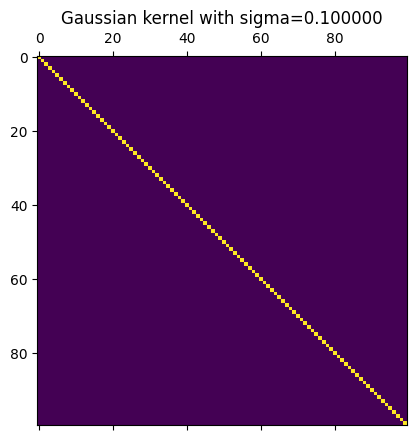

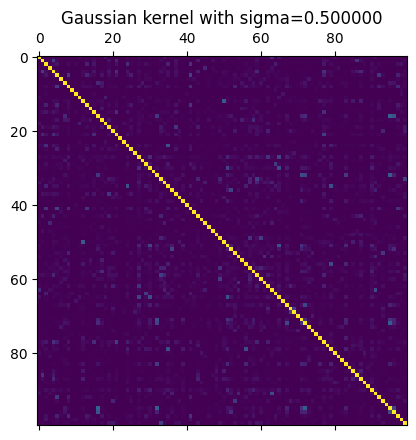

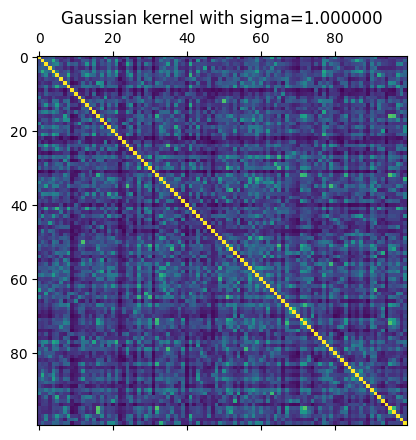

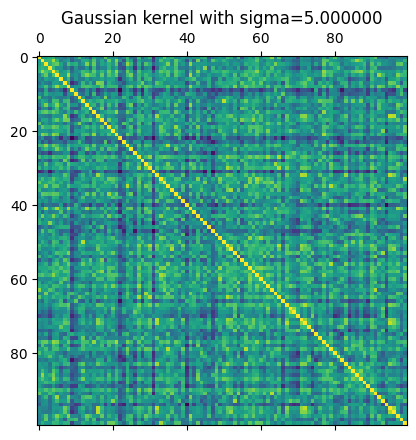

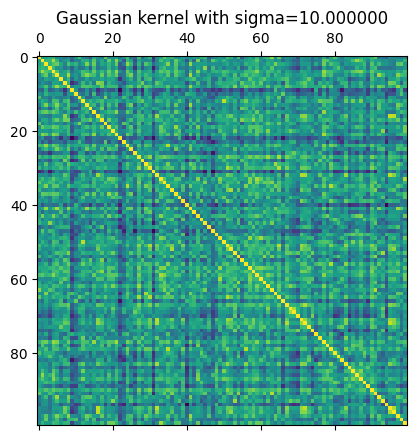

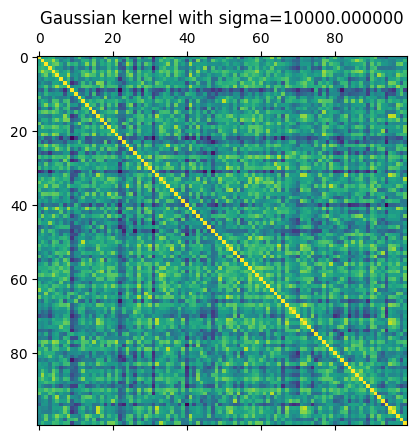

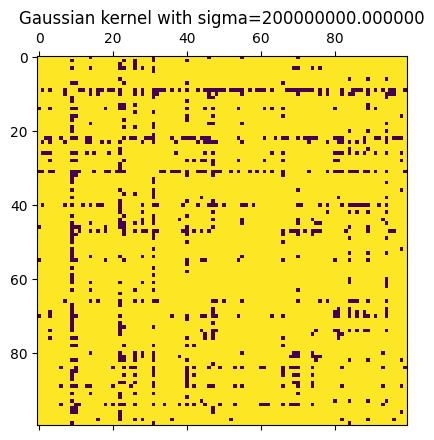

In [11]:
D = np.random.randn(100, 5) #Creates a random matrix with N(0,1) entries of dimension (100, 5)
lengthscale = [0.1, 0.5, 1, 5, 10.0, 10000.0, 200000000.0]

for leng in lengthscale:
  K = kernel_matrix(D, D, 'gaussian', leng)
  fig, ax = plt.subplots()
  ax.matshow(K)
  ax.set_title("Gaussian kernel with sigma=%f" % (leng))

#sigma piccolo : vede i punti molto distanti, ad eccezione della diagonale tutti i punti sono distanti
#sigma grande : l'esponenziale va a 1, i punti li classifica tutti vicini (VD FOTO)
#da valutare trade off tra distanza xi e xj e parametro lenghtscale (se param > di distanza , tutti i casi ), il lenghtscale funziona un pò come il parametro di regolarizzazione , per trovare quello ottimale => C-V
#giallo=1 , viola=0

## Implement Kernel RLS

Remember that, given kernel $K = k(x_i, x_j)$ for $i=(1, \dots, n)$ and $j=(1, \dots, n)$, KRLS learns a weight-vector with the following formula

$$(K + n \lambda I)w = Y$$

and then predictions on some new point $\tilde{x}$ are given by

$$f^{\mathrm{KRLS}}(\tilde{x}) = k(\tilde{x}, X^{\mathrm{train}}) w$$

In [12]:
def krls_train(x, y, reg_par, kernel_type, kernel_par):
    n = x.shape[0]
    lhs = kernel_matrix(x, x, kernel_type, kernel_par) + reg_par*n*np.eye(n) #lhs= K+lam*n*I
    w = np.linalg.solve(lhs, y)
    return w

def krls_predict(x_test, x_tr, w, kernel_type, kernel_par):
    y_pred = kernel_matrix(x_test, x_tr, kernel_type, kernel_par) @ w   #w sarebbe c della nostra teoria
    return y_pred

Now test the functions you have implemented on the quadratic dataset.

**Tasks:**
 1. use the linear kernel, can you fit the data?
 2. use the polynomial kernel, test the effect of the kernel parameter on the results:
    - describe what happens with a low/high exponent in terms of the bias-variance tradeoff.
 3. use the polynomial kernel, but fix the kernel parameter. Test the effect of the regularization parameter
    - describe what happens with a low/high regularizer in terms of the bias-variance tradeoff

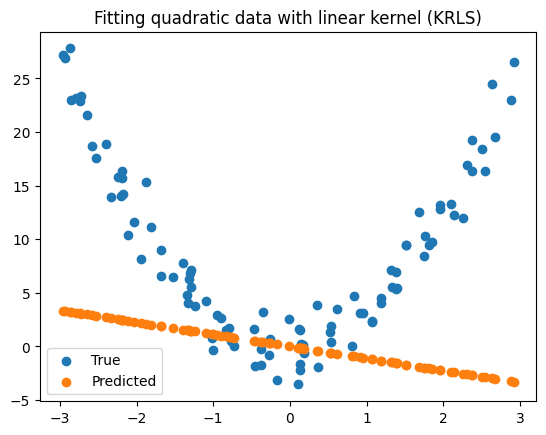

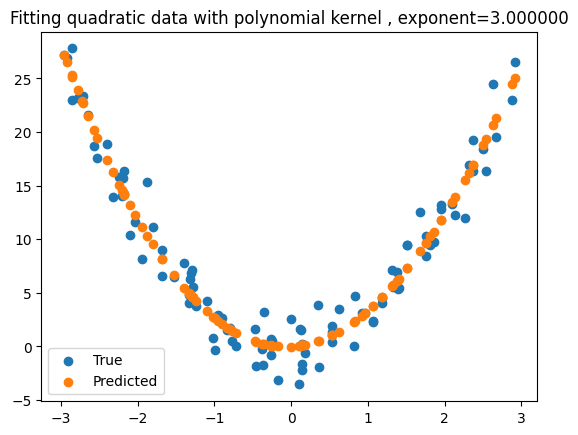

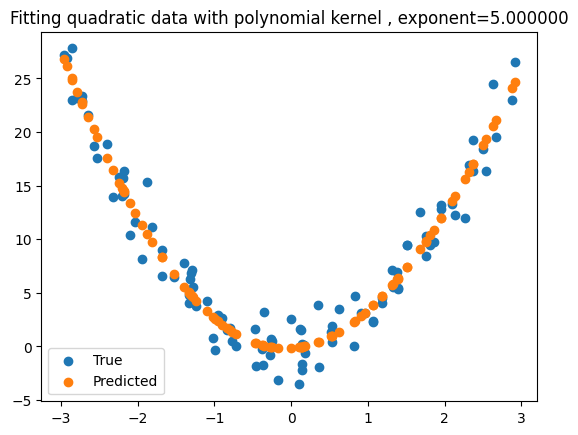

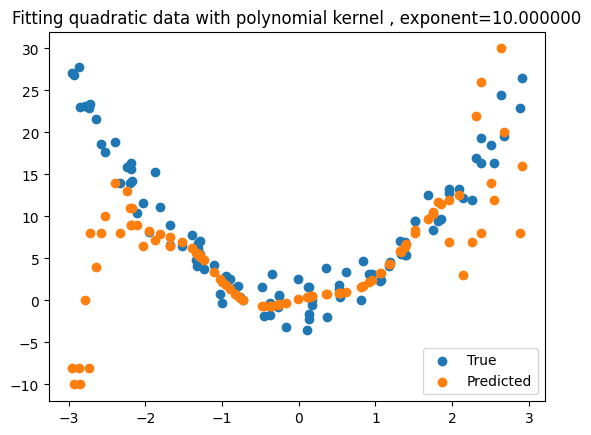

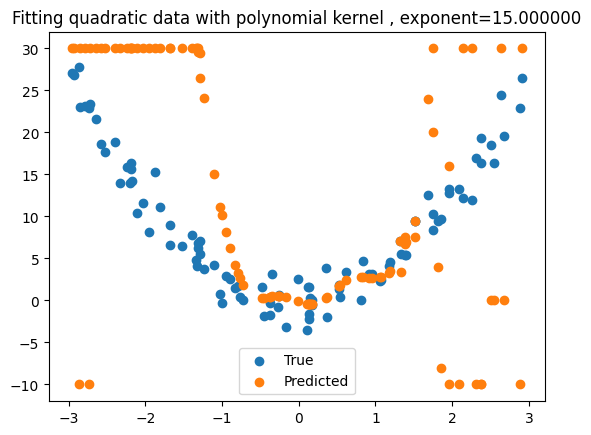

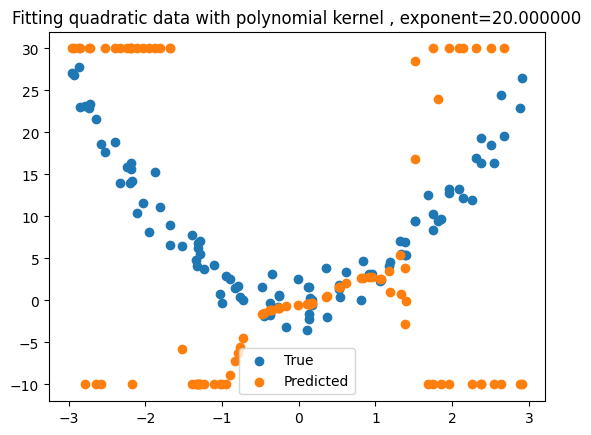

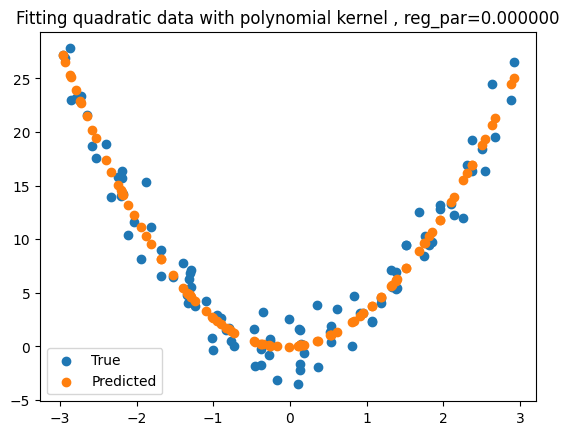

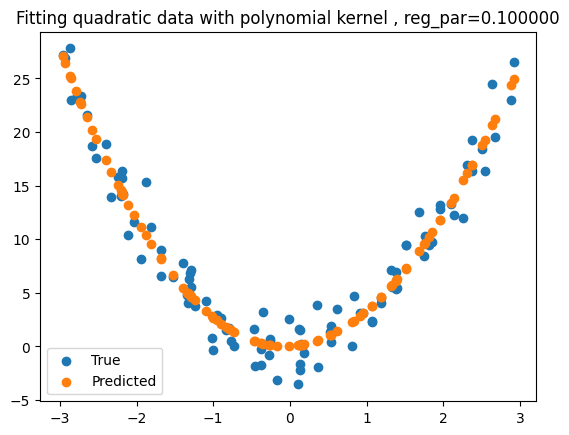

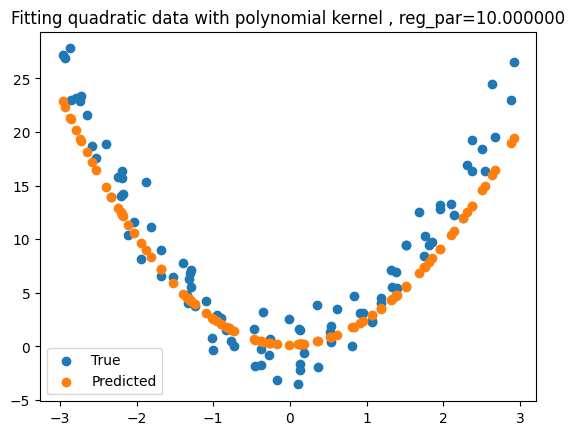

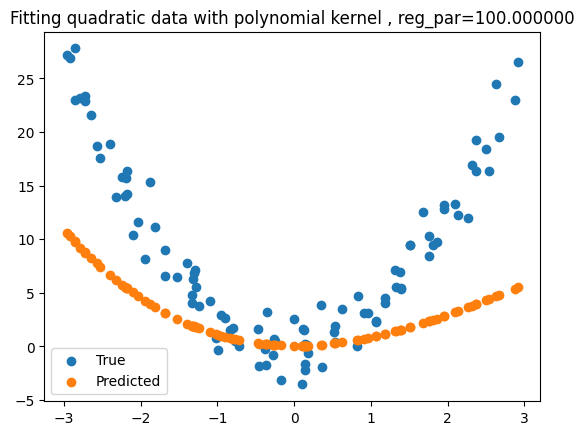

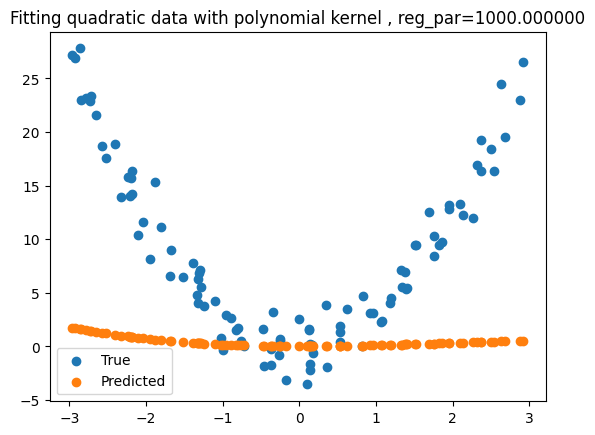

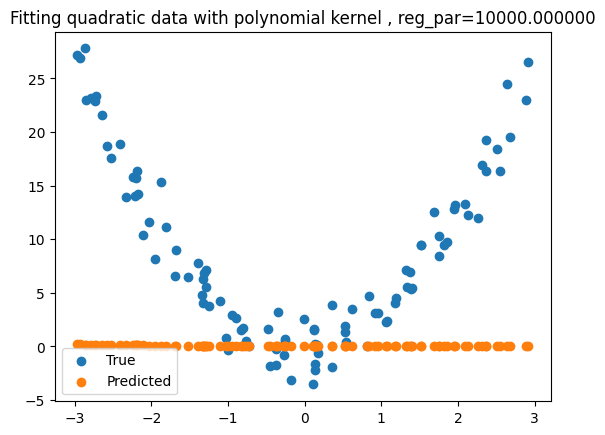

In [13]:
x_tr, y_tr = quadratic_data_gen(100, np.array([3]), 2.0)

ker_par = 3.0
reg_param = 1e-9

#LINEAR
w_krls = krls_train(x_tr, y_tr, reg_param, "linear", ker_par)
ypred_tr = krls_predict(x_tr, x_tr, w_krls, "linear" , ker_par)

fig, ax = plt.subplots()
ax.scatter(x_tr, y_tr, label="True")
ax.scatter(x_tr, ypred_tr, label="Predicted")
ax.legend(loc="best")
ax.set_title('Fitting quadratic data with linear kernel (KRLS)')

#POLYNOMIAL
#effetto parametro kernel
ker_par=[3, 5, 10, 15, 20]
for k in ker_par:
  w_krls = krls_train(x_tr, y_tr, reg_param, "polynomial", k)
  ypred_tr = krls_predict(x_tr, x_tr, w_krls, "polynomial" , k)
  y_tr_clipped = np.clip(y_tr, -10, 30)
  ypred_tr_clipped = np.clip(ypred_tr, -10, 30)

  fig, ax = plt.subplots()
  ax.scatter(x_tr, y_tr_clipped, label="True")
  ax.scatter(x_tr, ypred_tr_clipped, label="Predicted")
  ax.legend(loc="best")
  ax.set_title("Fitting quadratic data with polynomial kernel , exponent=%f" % (k))

#EFFETTO PARAMETRO di REGOLARIZZAZIONE
reg_param=[1e-9, 1e-1, 10, 100, 1000, 10000]
for reg in reg_param:
  w_krls = krls_train(x_tr, y_tr, reg, "polynomial", 3)
  ypred_tr = krls_predict(x_tr, x_tr, w_krls, "polynomial" , 3)

  fig, ax = plt.subplots()
  ax.scatter(x_tr, y_tr, label="True")
  ax.scatter(x_tr, ypred_tr, label="Predicted")
  ax.legend(loc="best")
  ax.set_title("Fitting quadratic data with polynomial kernel , reg_par=%f" % (reg))

## Generating a more complex non-linear dataset

Define a function to generate a d-dimensional synthetic dataset where the targets `Y` depend non-linearly on the variables `X`.

The parameters of the function are:
 - n : the number of samples
 - d : the dimension of the samples
 - low_d : the lower-bound for the uniformly distributed samples
 - high_d : the higher-bound for the uniformly distributed samples
 - sigma_noise : standard deviation of Gaussian noise added to the targets

It should return:
 - X : 2D array of size n, d which fits in the desired bounds
 - Y : 2D array of size n, 1 which is a non-linear function of `X` (and a linear function of `w`)

Examples of non-linear regression functions:
 - polynomial dependence of the Y on the X data
 - logarithmic dependence
 - more complex transforms (e.g. trig functions)


In [14]:
def nonlinear_data_gen(n, d, low_d, high_d, sigma_noise):
    X = np.random.uniform(low=low_d, high=high_d, size=(n, d))
    assert X.shape == (n, d), "Shape of X incorrect"
    Y = np.sinc(np.linalg.norm(X, axis=1)).reshape(-1, 1)# but try with other options! sinc = sen(pi*x)/pi*x , log, exp, cosh, arctanh
    assert Y.shape == (n, 1), "Shape of Y incorrect"

    # Add noise
    noise = np.random.normal(0, sigma_noise, size=(n, 1))
    Y_noisy = Y + noise

    return X, Y_noisy

## KRLS and cross-validation
Now we will use KRLS and k-fold CV to learn on the complex non-linear datasets we have generated.

In this last part you will have to do the following:
 1. Generate a non-linear dataset, find the best hyperparameters (using e.g. the Gaussian kernel) with the training set, and then use them to make predictions on the test-set. Are you able to fit your data well?
 2. Analyse how the amount of noise (see the `sigma_noise` parameter of `nonlinear_data_gen`) influences the best lambda as selected by cross-validation. In particular answer to the following question:
     - How does the best lambda change as you increase/decrease the amount of noise in your dataset? Why?
     
    **Hint: keep the kernel parameter fixed for this third task, otherwise it might be very hard to see**

In [15]:
def krls_kfold_valerr(x_tr, y_tr, num_folds, reg_par, kernel_type, kernel_par):
    """
    Compute the k-fold cross-validation error for one KRLS model (with speficied regularization,
    kernel and kernel parameter).

    This function returns both the training errors and the validation errors
    obtained from CV (as numpy arrays).
    """
    if num_folds <= 1:
        raise Exception("Please supply a number of folds > 1")
    if num_folds > x_tr.shape[0]:
        raise ValueError("Number of folds cannot be greater than the number of samples.")

    n_tot = x_tr.shape[0]
    n_val = int(n_tot // num_folds) # // performs the floor division, outputs a float

    tr_errs, val_errs = [], []
    # `split_idx`: a list of arrays, each containing the validation indices for 1 fold
    rand_idx = np.random.choice(n_tot, size=n_tot, replace=False)
    split_idx = np.array_split(rand_idx, num_folds)
    for fold in range(num_folds):
        # Set the indices in boolean mask for all validation samples to `True`
        val_mask = np.zeros(n_tot, dtype=bool)
        val_mask[split_idx[fold]] = True

        kf_x_tr = x_tr[~val_mask]
        kf_y_tr = y_tr[~val_mask]
        kf_x_val = x_tr[val_mask]
        kf_y_val = y_tr[val_mask]

        w_krls = krls_train(kf_x_tr, kf_y_tr, reg_par=reg_par, kernel_type=kernel_type, kernel_par=kernel_par)

        pred_val = krls_predict(kf_x_val, kf_x_tr, w_krls, kernel_type=kernel_type, kernel_par=kernel_par)
        val_errs.append(calc_err(pred_val, kf_y_val))
    return np.mean(np.asarray(val_errs))

In [16]:
def krls_kfoldcv(x_tr, y_tr, num_folds, reg_par_list, kernel_type, kernel_par_list):
    """Choose the best parameters for both the regularizer and the kernel parameter according to K-Fold CV.
    """
    errors = np.zeros((len(reg_par_list), len(kernel_par_list)))
    for i, reg_par in enumerate(reg_par_list):
        for j, kernel_par in enumerate(kernel_par_list):
            errors[i, j] = krls_kfold_valerr(x_tr, y_tr, num_folds, reg_par, kernel_type, kernel_par)

    best_reg_par = reg_par_list[np.unravel_index(np.argmin(errors), errors.shape)[0]]
    best_kernel_par = kernel_par_list[np.unravel_index(np.argmin(errors), errors.shape)[1]]
    best_err = np.min(errors)
    print(f"The best error (MSE={best_err*100:.2f}%) was obtained with "
          f"lambda={best_reg_par}, kernel_parameter={best_kernel_par}")
    return best_reg_par, best_kernel_par, best_err

The best error (MSE=1.05%) was obtained with lambda=1.2915496650148827e-06, kernel_parameter=10.0
The MSE on the test data is: 1.27%


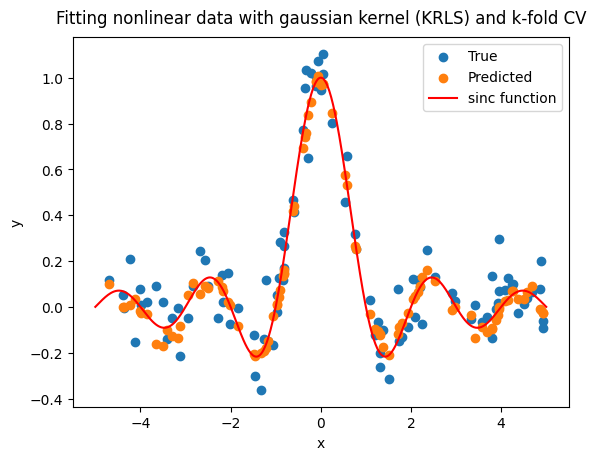

In [17]:
# Data gen parameters

n_tr = 400
n_test = 100
d = 1
low_d = -5
high_d = 5
sigma_noise = 0.1

x_tr, y_tr = nonlinear_data_gen(n_tr, d, low_d, high_d, sigma_noise)
x_test, y_test = nonlinear_data_gen(n_test, d, low_d, high_d, sigma_noise)


# K_fold parameters
num_folds = 5
reg_par_list = np.logspace(-7,3,10)
ker_type = 'gaussian'
ker_par_list = np.logspace(-3,3,10)

# Compute HERE the best kernel parameter and the best regularization parameter (use krls_kfoldcv!)
best_reg_par, best_kernel_par, _ = krls_kfoldcv(x_tr, y_tr, num_folds, reg_par_list, ker_type, ker_par_list)

# Now retrain on the whole of x_tr with the best parameters and test on x_ts!
w_krls = krls_train(x_tr, y_tr, best_reg_par, ker_type, best_kernel_par)
y_pred = krls_predict(x_test, x_tr, w_krls, ker_type, best_kernel_par)
test_error = calc_err(y_pred, y_test)
print(f'The MSE on the test data is: {test_error*100:.2f}%')

x_sinc = np.linspace(low_d, high_d, 500)
y_sinc = np.sinc(x_sinc)  #se cambio funzione cambio

#visualization
plt.scatter(x_test, y_test, label='True')
plt.scatter(x_test, y_pred, label='Predicted')
plt.plot(x_sinc, y_sinc, 'r-', label='sinc function')
plt.legend()
plt.title('Fitting nonlinear data with gaussian kernel (KRLS) and k-fold CV', pad=10)
plt.xlabel('x')
plt.ylabel('y')
plt.show()

Noise in data = 0.001
The best error (MSE=0.00%) was obtained with lambda=2.2122162910704503e-08, kernel_parameter=10.0
The MSE test error is: 4.1874495497037116e-06

Best lambda is: 2.2122162910704503e-08

Noise in data = 0.01
The best error (MSE=0.01%) was obtained with lambda=2.395026619987486e-07, kernel_parameter=10.0
The MSE test error is: 0.00010916633822979539

Best lambda is: 2.395026619987486e-07

Noise in data = 0.1
The best error (MSE=1.19%) was obtained with lambda=2.592943797404667e-06, kernel_parameter=10.0
The MSE test error is: 0.011006946425160691

Best lambda is: 2.592943797404667e-06

Noise in data = 0.2
The best error (MSE=4.09%) was obtained with lambda=1.2689610031679234e-05, kernel_parameter=10.0
The MSE test error is: 0.039153254928406614

Best lambda is: 1.2689610031679234e-05

Noise in data = 0.5
The best error (MSE=26.84%) was obtained with lambda=1.2689610031679234e-05, kernel_parameter=10.0
The MSE test error is: 0.25522875393867667

Best lambda is: 1.2689

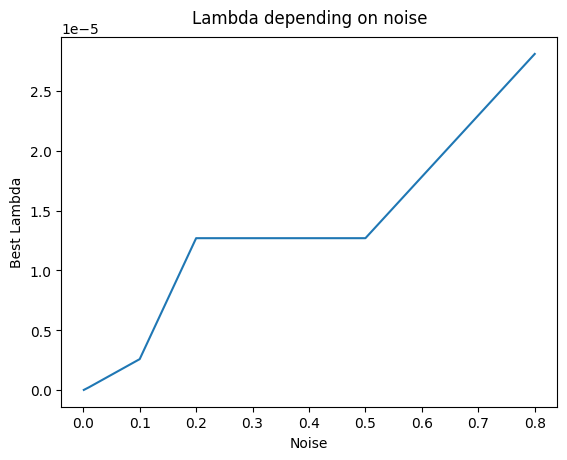

In [18]:
# TODO: Analyse the effect of noise!
reg_par_list = np.logspace(-8,2,30)
kernel_par_list = [best_kernel_par]#kernel parameter fixed for this task, the best we found before
kernel_type = 'gaussian'
num_folds = 4
lam_arr = []
noises = [0.001, 0.01, 0.1, 0.2, 0.5, 0.8]


for noise in noises:

    x_tr, y_tr = nonlinear_data_gen(400, 1, -5, 5, noise)
    x_test, y_test = nonlinear_data_gen(100, 1, -5, 5, noise)

    print("Noise in data = {}".format(noise))
    best_reg_par, best_kernel_par, _ = krls_kfoldcv(x_tr, y_tr, num_folds, reg_par_list, kernel_type, kernel_par_list)
    lam_arr.append(best_reg_par)

    # Now retrain on the whole of x_tr with the best parameters and test on x_ts!
    w_krls = krls_train(x_tr, y_tr, reg_par=best_reg_par, kernel_type=kernel_type, kernel_par=best_kernel_par)
    y_pred = krls_predict(x_test, x_tr, w_krls, kernel_type=kernel_type, kernel_par=best_kernel_par)
    test_error = calc_err(y_pred, y_test)

    print("The MSE test error is: {}\n".format(test_error))
    print("Best lambda is: {}\n".format(best_reg_par))

#Plot lambda depending on noise
print()
plt.figure()
plt.plot(noises, lam_arr)
plt.title('Lambda depending on noise', pad=10)
plt.xlabel('Noise')
plt.ylabel('Best Lambda')
plt.show()

The best error (MSE=3.09%) was obtained with lambda=0.0027825594022071257, kernel_parameter=10
The MSE on the test data is: 3.88%


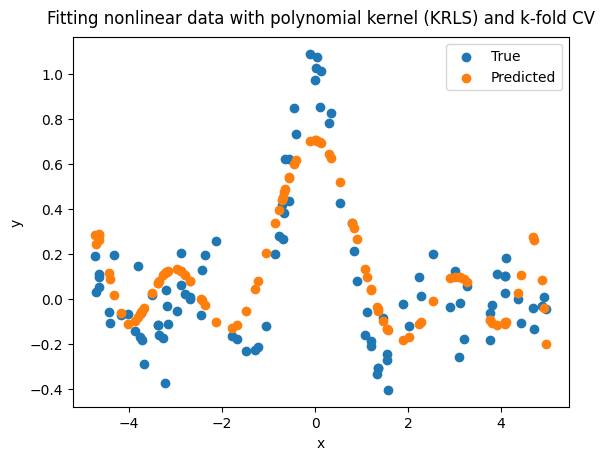

Noise in data = 0.001
The best error (MSE=0.00%) was obtained with lambda=1e-07, kernel_parameter=10.0


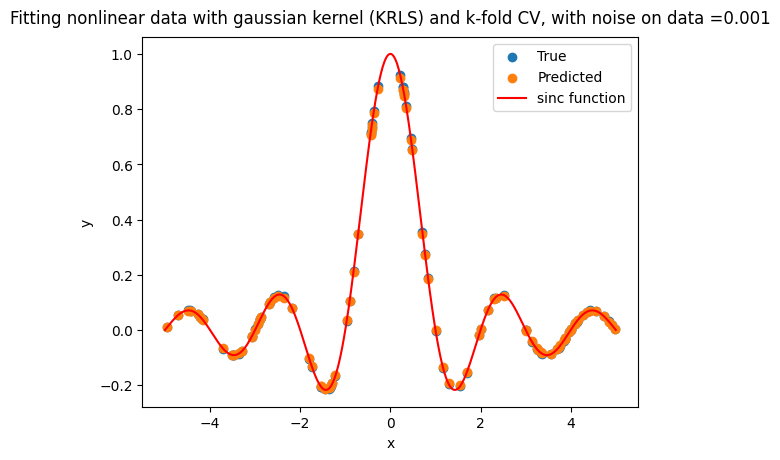

Noise in data = 0.01
The best error (MSE=0.01%) was obtained with lambda=1e-07, kernel_parameter=10.0


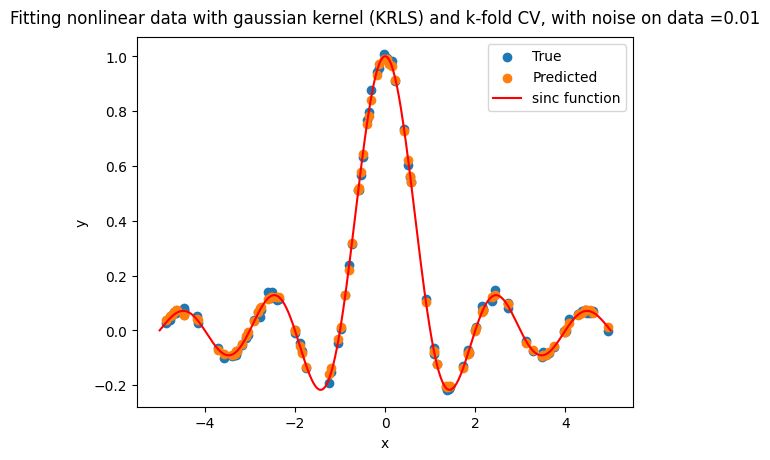

Noise in data = 0.1
The best error (MSE=1.15%) was obtained with lambda=1.2915496650148827e-06, kernel_parameter=10.0


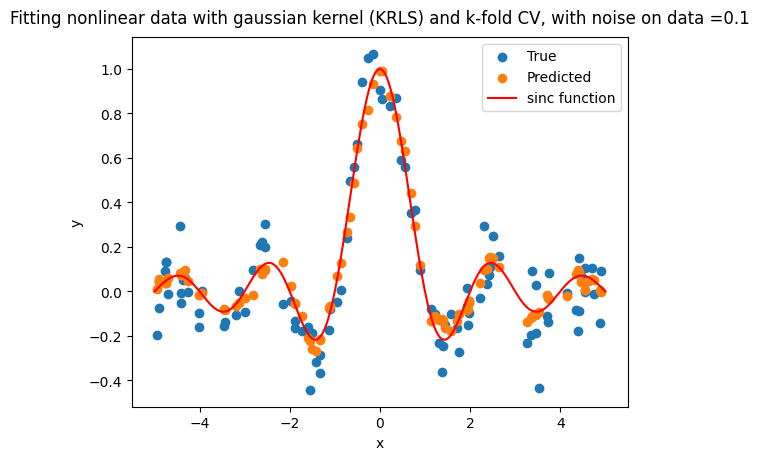

Noise in data = 0.2
The best error (MSE=4.03%) was obtained with lambda=1.6681005372000593e-05, kernel_parameter=10.0


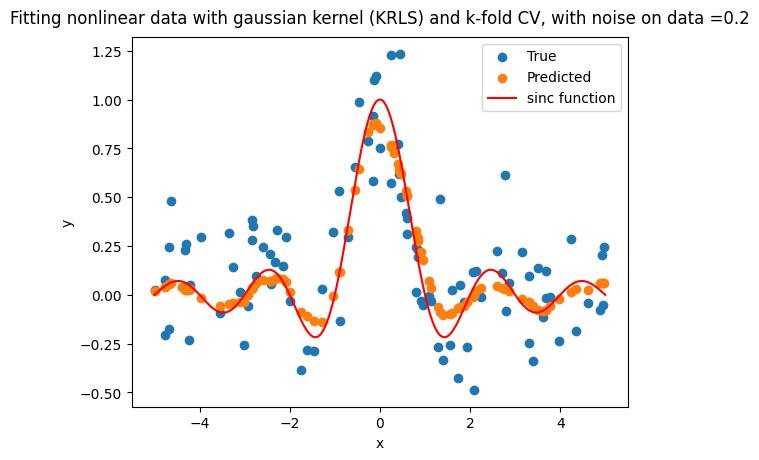

Noise in data = 0.5
The best error (MSE=24.87%) was obtained with lambda=1.6681005372000593e-05, kernel_parameter=10.0


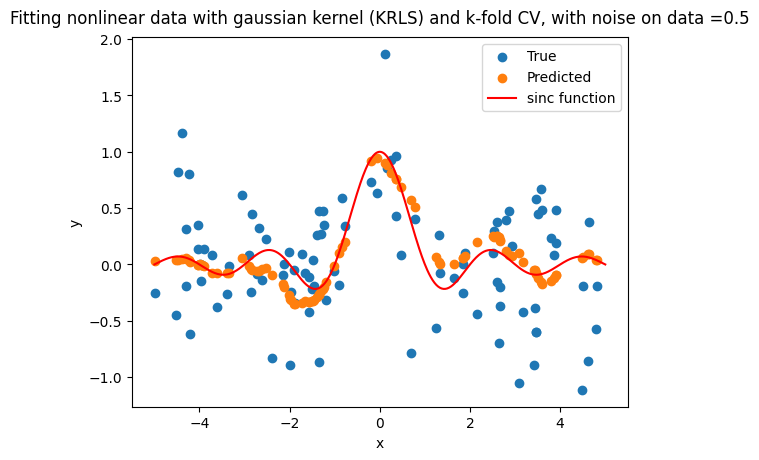

In [19]:
# Data gen parameters

n_tr = 400
n_test = 100
d = 1
low_d = -5
high_d = 5
sigma_noise = 0.1

x_tr, y_tr = nonlinear_data_gen(n_tr, d, low_d, high_d, sigma_noise)
x_test, y_test = nonlinear_data_gen(n_test, d, low_d, high_d, sigma_noise)


# K_fold parameters , bene con exp e sinc, male con log
num_folds = 5
reg_par_list = np.logspace(-7,3,10)
ker_type = 'polynomial'
ker_par_list = range(1,11)

# Compute HERE the best kernel parameter and the best regularization parameter (use krls_kfoldcv!)
best_reg_par, best_kernel_par, _ = krls_kfoldcv(x_tr, y_tr, num_folds, reg_par_list, ker_type, ker_par_list)

# Now retrain on the whole of x_tr with the best parameters and test on x_ts!
w_krls = krls_train(x_tr, y_tr, best_reg_par, ker_type, best_kernel_par)
y_pred = krls_predict(x_test, x_tr, w_krls, ker_type, best_kernel_par)
test_error = calc_err(y_pred, y_test)
print(f'The MSE on the test data is: {test_error*100:.2f}%')


#visualization
plt.scatter(x_test, y_test, label='True')
plt.scatter(x_test, y_pred, label='Predicted')
plt.legend()
plt.title('Fitting nonlinear data with polynomial kernel (KRLS) and k-fold CV', pad=10)
plt.xlabel('x')
plt.ylabel('y')
plt.show()

####### PREDIZIONI DEL MODELLO AL VARIARE DELLA PERCENTUALE DI RUMORE NEI DATI CON BEST LAM E BEST KER PAR

n_tr = 400
n_test = 100
d = 1
low_d = -5
high_d = 5
sigma_noise = [0.001, 0.01, 0.1, 0.2, 0.5]


# K_fold parameters
num_folds = 5
reg_par_list = np.logspace(-7,3,10)
ker_type = 'gaussian'
ker_par_list = np.logspace(-3,3,10)

for noise in sigma_noise:

    x_tr, y_tr = nonlinear_data_gen(400, 1, -5, 5, noise)
    x_test, y_test = nonlinear_data_gen(100, 1, -5, 5, noise)

    print("Noise in data = {}".format(noise))
    best_reg_par, best_kernel_par, _ = krls_kfoldcv(x_tr, y_tr, num_folds, reg_par_list, kernel_type, kernel_par_list)
    lam_arr.append(best_reg_par)

    # Now retrain on the whole of x_tr with the best parameters and test on x_ts!
    w_krls = krls_train(x_tr, y_tr, reg_par=best_reg_par, kernel_type=kernel_type, kernel_par=best_kernel_par)
    y_pred = krls_predict(x_test, x_tr, w_krls, kernel_type=kernel_type, kernel_par=best_kernel_par)
    test_error = calc_err(y_pred, y_test)

    plt.scatter(x_test, y_test, label='True')
    plt.scatter(x_test, y_pred, label='Predicted')
    plt.plot(x_sinc, y_sinc, 'r-', label='sinc function')
    plt.legend()
    plt.title(f"Fitting nonlinear data with gaussian kernel (KRLS) and k-fold CV, with noise on data ={noise}", pad=10)
    plt.xlabel('x')
    plt.ylabel('y')
    plt.show()

#Nonostante l'aumento del rumore sui dati , le predizioni effettuate utilizzando il parametro di regolarizzazione e
#quello di kernel  ,ottenute tramite CV, sono stabili rispetto alla funzione generatrice dei dati. Il modello
#capisce l'eccessivo aumento di rumore e procede a trovare i valori di regressione e kernel migliori per
#far si che le previsioni si adattino alla funzione genratrice dei dati